<a href="https://colab.research.google.com/github/kinjalmodi24/bananahacks_26/blob/main/RealPlate.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [1]:
print("RealPlate pipeline starting!")
print("Goal: Generate better food photos while preserving the original food.")

RealPlate pipeline starting!
Goal: Generate better food photos while preserving the original food.


In [2]:

import torch

print("PyTorch version:", torch.__version__)
print("GPU available:", torch.cuda.is_available())

if torch.cuda.is_available():
    print("GPU name:", torch.cuda.get_device_name(0))
else:
    print("Running on CPU for now.")


PyTorch version: 2.11.0+cu130
GPU available: True
GPU name: Tesla T4


In [3]:
%pip install -q transformers accelerate pillow matplotlib


In [4]:
import torch
import transformers
from PIL import Image
import matplotlib.pyplot as plt

print("GPU:", torch.cuda.get_device_name(0))
print("Transformers:", transformers.__version__)
print("All imports successful!")

GPU: Tesla T4
Transformers: 5.18.0
All imports successful!


Saving ocean-view-restaurant.jpg to ocean-view-restaurant (2).jpg
Uploaded: ocean-view-restaurant (2).jpg
Size (width x height): (1400, 800)


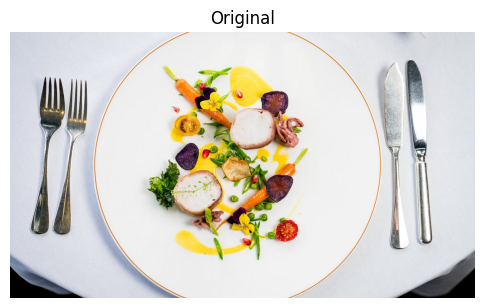

In [5]:
import numpy as np
from google.colab import files
from PIL import Image
import matplotlib.pyplot as plt

uploaded = files.upload()
image_path = next(iter(uploaded.keys()))

original = Image.open(image_path).convert("RGB")
print("Uploaded:", image_path)
print("Size (width x height):", original.size)

plt.figure(figsize=(6, 6))
plt.imshow(original)
plt.axis("off")
plt.title("Original")
plt.show()

Loading weights:   0%|          | 0/978 [00:00<?, ?it/s]

/usr/local/lib/python3.13/dist-packages/transformers/models/grounding_dino/processing_grounding_dino.py:94: FutureWarning: The key `labels` is will return integer ids in `GroundingDinoProcessor.post_process_grounded_object_detection` output since v4.51.0. Use `text_labels` instead to retrieve string object names.
  warnings.warn(self.message, FutureWarning)


a plate: score 0.81, box [248, 1, 1120, 795]


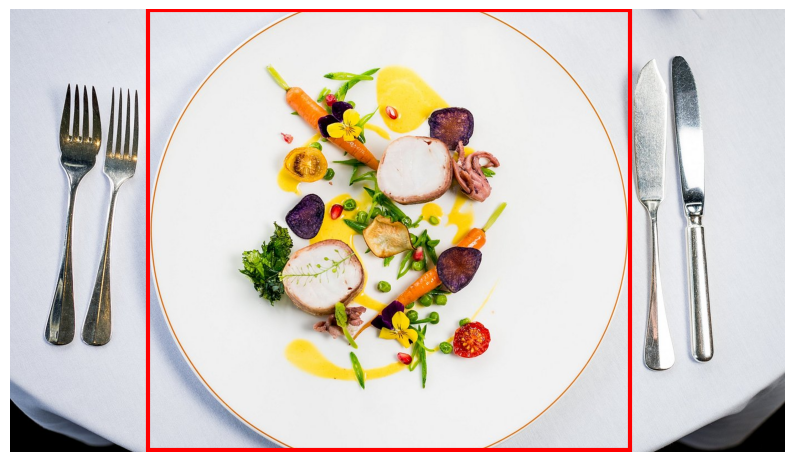

In [6]:
import torch
import matplotlib.patches as patches
from transformers import AutoProcessor, AutoModelForZeroShotObjectDetection

device = "cuda"
dino_id = "IDEA-Research/grounding-dino-tiny"
dino_processor = AutoProcessor.from_pretrained(dino_id)
dino_model = AutoModelForZeroShotObjectDetection.from_pretrained(dino_id).to(device)

text_prompt = "a plate."   # lowercase + period is the format this model expects
inputs = dino_processor(images=original, text=text_prompt, return_tensors="pt").to(device)

with torch.no_grad():
    outputs = dino_model(**inputs)

results = dino_processor.post_process_grounded_object_detection(
    outputs,
    input_ids=inputs.input_ids,
    threshold=0.3,
    text_threshold=0.25,
    target_sizes=[original.size[::-1]],   # (height, width)
)[0]

labels = results.get("text_labels", results.get("labels"))
for score, label, box in zip(results["scores"], labels, results["boxes"]):
    print(f"{label}: score {score:.2f}, box {[round(v) for v in box.tolist()]}")

fig, ax = plt.subplots(figsize=(10, 6))
ax.imshow(original)
for box in results["boxes"]:
    x0, y0, x1, y1 = box.tolist()
    ax.add_patch(patches.Rectangle((x0, y0), x1 - x0, y1 - y0, fill=False, edgecolor="red", linewidth=3))
ax.axis("off")
plt.show()

Loading weights:   0%|          | 0/314 [00:00<?, ?it/s]

SAM confidence: 0.964
Plate mask covers 37.6% of the image


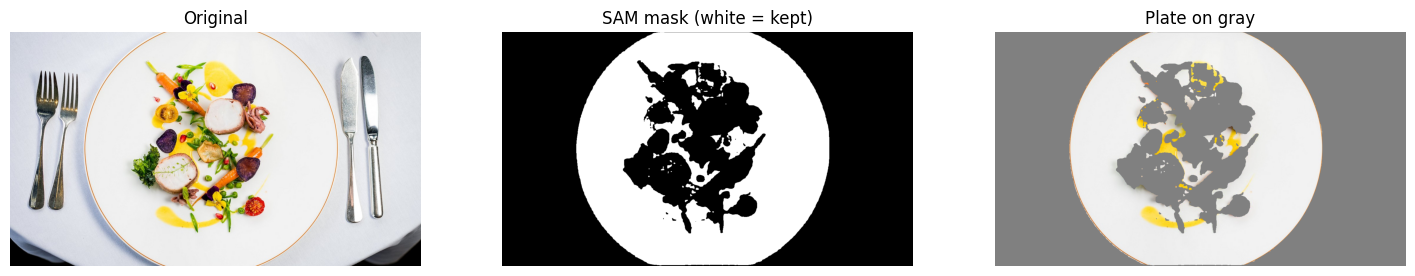

Mask covers:            37.6% of image
Mask extent (x0,y0,x1,y1): 253, 3, 1114, 797   (DINO box: 248, 1, 1120, 795)
Fill of DINO box:       60.8%   (a plate clipped top/bottom should be ~80-90%)
Pixels outside box:     504   (want ~0, else it grabbed cutlery/tablecloth)
Separate pieces:        41   (want 1)
Hole pixels inside:     145223   (want ~0, else food/sauce got cut out)


In [7]:
from transformers import SamModel, SamProcessor

sam_id = "facebook/sam-vit-base"
sam_processor = SamProcessor.from_pretrained(sam_id)
sam_model = SamModel.from_pretrained(sam_id).to(device)

# Use the highest-scoring plate box from Grounding DINO as SAM's prompt
best = results["scores"].argmax().item()
plate_box = results["boxes"][best].tolist()

sam_inputs = sam_processor(original, input_boxes=[[plate_box]], return_tensors="pt").to(device)
with torch.no_grad():
    sam_outputs = sam_model(**sam_inputs, multimask_output=False)

masks = sam_processor.post_process_masks(
    sam_outputs.pred_masks.cpu(),
    sam_inputs["original_sizes"].cpu(),
    sam_inputs["reshaped_input_sizes"].cpu(),
)
plate_mask = masks[0][0][0].numpy()   # True = plate pixel, False = background

print("SAM confidence:", round(sam_outputs.iou_scores[0, 0, 0].item(), 3))
print(f"Plate mask covers {plate_mask.mean() * 100:.1f}% of the image")

mask_img = Image.fromarray((plate_mask * 255).astype("uint8"))
gray = Image.new("RGB", original.size, (128, 128, 128))
preview = Image.composite(original, gray, mask_img)

fig, axes = plt.subplots(1, 3, figsize=(18, 6))
for ax, img, title in zip(axes, [original, mask_img, preview], ["Original", "SAM mask (white = kept)", "Plate on gray"]):
    ax.imshow(img, cmap="gray" if img is mask_img else None)
    ax.set_title(title)
    ax.axis("off")
plt.show()
from scipy import ndimage

def mask_report(mask, box):
    """Text summary of mask quality so we don't need screenshots."""
    m = mask.astype(bool)
    h, w = m.shape
    x0, y0, x1, y1 = [int(round(v)) for v in box]

    _, n_parts = ndimage.label(m)
    holes = ndimage.binary_fill_holes(m) & ~m
    outside_box = m.copy()
    outside_box[y0:y1, x0:x1] = False
    inside_box = m[y0:y1, x0:x1].mean()

    ys, xs = np.where(m)
    print(f"Mask covers:            {m.mean() * 100:.1f}% of image")
    print(f"Mask extent (x0,y0,x1,y1): {xs.min()}, {ys.min()}, {xs.max()}, {ys.max()}   (DINO box: {x0}, {y0}, {x1}, {y1})")
    print(f"Fill of DINO box:       {inside_box * 100:.1f}%   (a plate clipped top/bottom should be ~80-90%)")
    print(f"Pixels outside box:     {outside_box.sum()}   (want ~0, else it grabbed cutlery/tablecloth)")
    print(f"Separate pieces:        {n_parts}   (want 1)")
    print(f"Hole pixels inside:     {holes.sum()}   (want ~0, else food/sauce got cut out)")

mask_report(plate_mask, plate_box)

Mask covers:            50.6% of image
Mask extent (x0,y0,x1,y1): 253, 3, 1114, 795   (DINO box: 248, 1, 1120, 795)
Fill of DINO box:       81.8%   (a plate clipped top/bottom should be ~80-90%)
Pixels outside box:     332   (want ~0, else it grabbed cutlery/tablecloth)
Separate pieces:        1   (want 1)
Hole pixels inside:     0   (want ~0, else food/sauce got cut out)


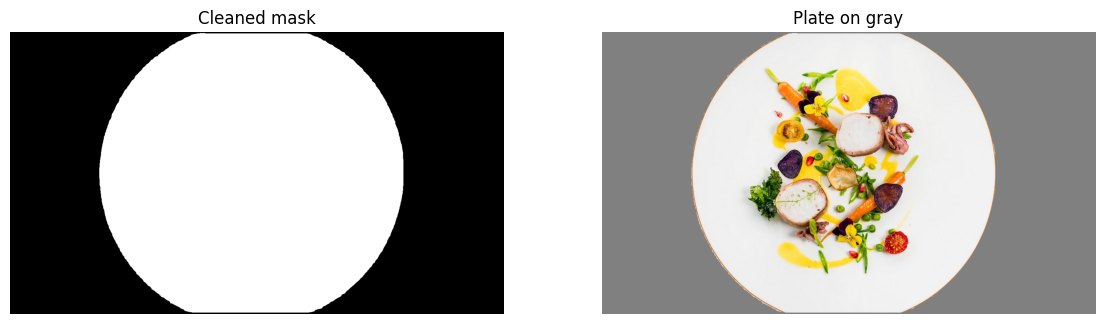

In [8]:
def clean_mask(mask, box):
    m = ndimage.binary_fill_holes(mask.astype(bool))          # 1. food holes -> filled

    labeled, n = ndimage.label(m)                              # 2. keep largest piece
    if n > 1:
        sizes = ndimage.sum(m, labeled, range(1, n + 1))
        m = labeled == (np.argmax(sizes) + 1)

    x0, y0, x1, y1 = [int(round(v)) for v in box]              # 3. clip to the plate box
    inside = np.zeros_like(m)
    inside[y0:y1 + 1, x0:x1 + 1] = True
    m &= inside

    return ndimage.binary_fill_holes(m)                       # fill once more in case clipping opened anything

final_mask = clean_mask(plate_mask, plate_box)
mask_report(final_mask, plate_box)

final_mask_img = Image.fromarray((final_mask * 255).astype("uint8"))
preview = Image.composite(original, gray, final_mask_img)

fig, axes = plt.subplots(1, 2, figsize=(14, 5))
axes[0].imshow(final_mask_img, cmap="gray"); axes[0].set_title("Cleaned mask"); axes[0].axis("off")
axes[1].imshow(preview); axes[1].set_title("Plate on gray"); axes[1].axis("off")
plt.show()

In [9]:
# Save the mask to disk so we don't lose it if the session restarts
final_mask_img.save("plate_mask.png")
print("Mask saved.")

%pip install -q diffusers

Mask saved.


In [10]:
from importlib.metadata import version
import torch, numpy

print("diffusers:", version("diffusers"))
print("torch:", torch.__version__, "| GPU:", torch.cuda.is_available())
print("numpy:", numpy.__version__)

from diffusers import AutoPipelineForInpainting
print("diffusers imported OK")

diffusers: 0.40.0
torch: 2.11.0+cu130 | GPU: True
numpy: 2.1.3


[transformers] `Siglip2ImageProcessorFast` is deprecated. The `Fast` suffix for image processors has been removed; use `Siglip2ImageProcessor` instead.


diffusers imported OK


/usr/local/lib/python3.13/dist-packages/huggingface_hub/utils/_validators.py:206: UserWarning: The `local_dir_use_symlinks` argument is deprecated and ignored in `hf_hub_download`. Downloading to a local directory does not use symlinks anymore.
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/diffusers/utils/deprecation_utils.py:23: FutureWarning: `torch_dtype` is deprecated and will be removed in version 1.0.0. Please use `dtype` instead.
  deprecate("torch_dtype", "1.0.0", _TORCH_DTYPE_DEPRECATION_MESSAGE)


Loading pipeline components...:   0%|          | 0/7 [00:00<?, ?it/s]

Loading weights:   0%|          | 0/517 [00:00<?, ?it/s]

The config attributes {'decay': 0.9999, 'inv_gamma': 1.0, 'min_decay': 0.0, 'optimization_step': 37000, 'power': 0.6666666666666666, 'update_after_step': 0, 'use_ema_warmup': False} were passed to UNet2DConditionModel, but are not expected and will be ignored. Please verify your config.json configuration file.


Loading weights:   0%|          | 0/196 [00:00<?, ?it/s]

  0%|          | 0/29 [00:00<?, ?it/s]

Generation took 26.0 s


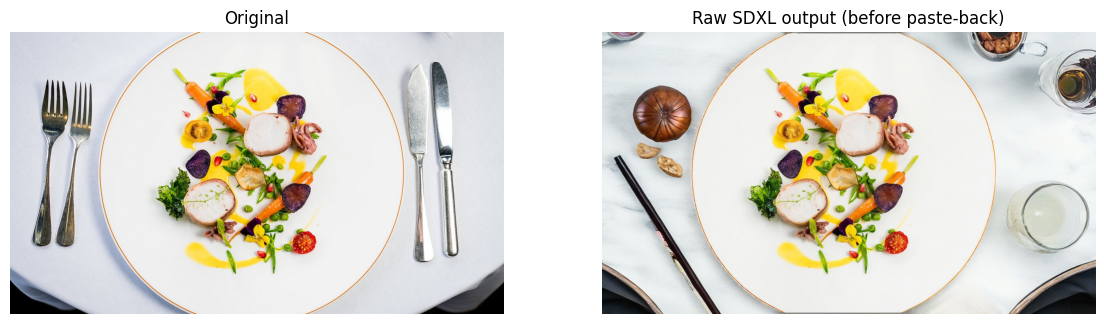

In [11]:
import time
from diffusers import AutoPipelineForInpainting

pipe = AutoPipelineForInpainting.from_pretrained(
    "diffusers/stable-diffusion-xl-1.0-inpainting-0.1",
    torch_dtype=torch.float16,
    variant="fp16",
).to(device)

# SDXL works best around 1 megapixel, in multiples of 64. 1344x768 keeps our 1400x800 shape.
GEN_W, GEN_H = 1344, 768
image_small = original.resize((GEN_W, GEN_H), Image.LANCZOS)

# Inpainting mask: WHITE = repaint, BLACK = keep. So it's the inverse of our plate mask.
bg_mask = Image.fromarray(((~final_mask) * 255).astype("uint8"))
bg_mask_small = bg_mask.resize((GEN_W, GEN_H), Image.NEAREST)

prompt = ("overhead view of a rustic dark walnut wooden table, warm soft natural window light, "
          "professional restaurant food photography, high detail")
negative_prompt = "food, plate, bowl, fork, knife, spoon, text, watermark, logo, people, hands, blurry"

generator = torch.Generator(device).manual_seed(42)   # fixed seed = same result every run
start = time.time()
generated_small = pipe(
    prompt=prompt,
    negative_prompt=negative_prompt,
    image=image_small,
    mask_image=bg_mask_small,
    width=GEN_W,
    height=GEN_H,
    strength=0.99,
    guidance_scale=7.5,
    num_inference_steps=30,
    generator=generator,
).images[0]
print(f"Generation took {time.time() - start:.1f} s")

generated = generated_small.resize(original.size, Image.LANCZOS)
generated.save("generated_raw.png")

fig, axes = plt.subplots(1, 2, figsize=(14, 5))
axes[0].imshow(original); axes[0].set_title("Original"); axes[0].axis("off")
axes[1].imshow(generated); axes[1].set_title("Raw SDXL output (before paste-back)"); axes[1].axis("off")
plt.show()

  0%|          | 0/29 [00:00<?, ?it/s]

Generation took 27.3 s


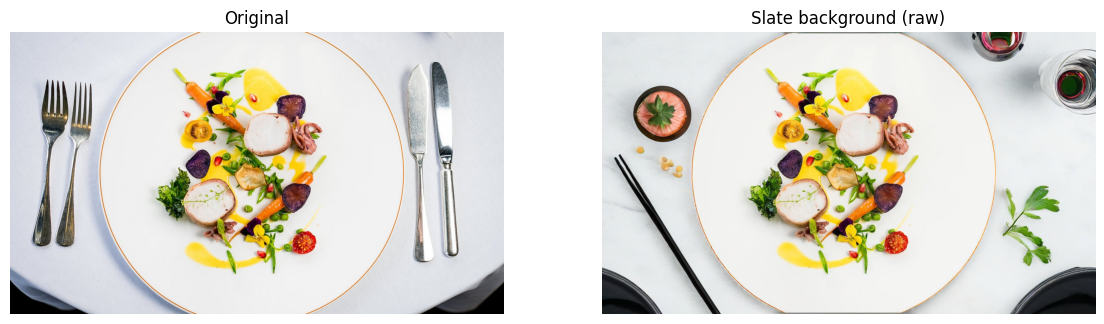

In [12]:
# Fine dining preset (teammate's doc, adapted: short + overhead angle)
prompt = ("overhead flat lay food photography, dark charcoal slate table surface with fine natural texture, "
          "soft even studio light, fine dining restaurant, photorealistic, high detail")
negative_prompt = ("plate, bowl, food, fork, knife, spoon, cutlery, napkin, glass, text, watermark, logo, "
                   "hands, fingers, people, clutter, blurry, low resolution, artifacts")

generator = torch.Generator(device).manual_seed(42)
start = time.time()
generated_small = pipe(
    prompt=prompt,
    negative_prompt=negative_prompt,
    image=image_small,
    mask_image=bg_mask_small,
    width=GEN_W,
    height=GEN_H,
    strength=0.99,
    guidance_scale=7.5,
    num_inference_steps=30,
    generator=generator,
).images[0]
print(f"Generation took {time.time() - start:.1f} s")

generated = generated_small.resize(original.size, Image.LANCZOS)
generated.save("generated_slate.png")

fig, axes = plt.subplots(1, 2, figsize=(14, 5))
axes[0].imshow(original); axes[0].set_title("Original"); axes[0].axis("off")
axes[1].imshow(generated); axes[1].set_title("Slate background (raw)"); axes[1].axis("off")
plt.show()

  0%|          | 0/30 [00:00<?, ?it/s]

Generation took 28.4 s


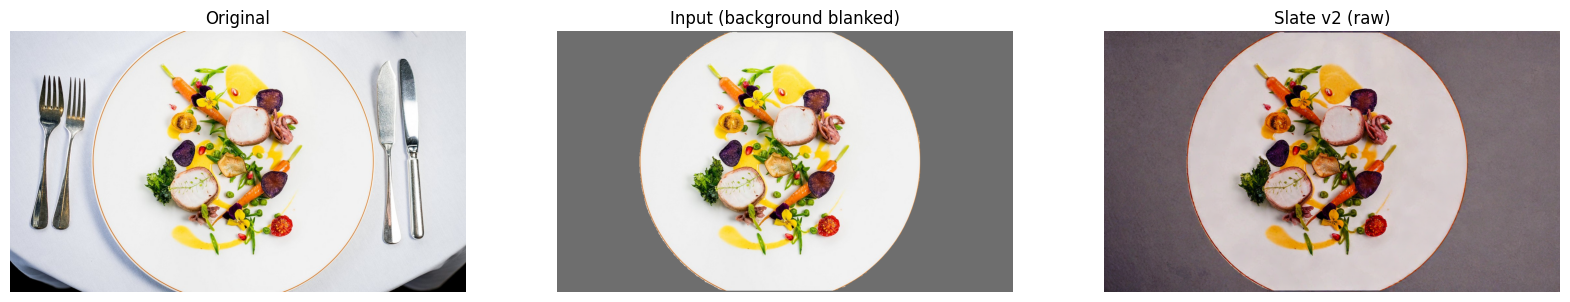

In [13]:
# 1. Replace everything outside the plate with flat gray (no white cloth, no cutlery shapes left)
blank_bg = Image.new("RGB", original.size, (110, 110, 110))
filled = Image.composite(original, blank_bg, final_mask_img)
filled_small = filled.resize((GEN_W, GEN_H), Image.LANCZOS)

prompt = ("overhead flat lay food photography, empty dark charcoal slate tabletop with fine natural stone texture, "
          "minimalist, soft even studio light, fine dining, photorealistic, high detail")
negative_prompt = ("plate, bowl, food, fork, knife, spoon, chopsticks, cup, glass, drink, wine, herbs, garnish, "
                   "napkin, props, marble, white, text, watermark, hands, clutter, blurry, artifacts")

generator = torch.Generator(device).manual_seed(42)
start = time.time()
generated_small = pipe(
    prompt=prompt,
    negative_prompt=negative_prompt,
    image=filled_small,          # gray-filled input instead of the original
    mask_image=bg_mask_small,
    width=GEN_W,
    height=GEN_H,
    strength=1.0,                # 2. repaint from scratch
    guidance_scale=7.5,
    num_inference_steps=30,
    generator=generator,
).images[0]
print(f"Generation took {time.time() - start:.1f} s")

generated = generated_small.resize(original.size, Image.LANCZOS)
generated.save("generated_slate_v2.png")

fig, axes = plt.subplots(1, 3, figsize=(20, 5))
axes[0].imshow(original); axes[0].set_title("Original"); axes[0].axis("off")
axes[1].imshow(filled); axes[1].set_title("Input (background blanked)"); axes[1].axis("off")
axes[2].imshow(generated); axes[2].set_title("Slate v2 (raw)"); axes[2].axis("off")
plt.show()

Plate/food pixels checked:   566,696
Plate/food pixels changed:   0  (0.0000%)
Background pixels changed:   100.0%
VERIFIED: food region is pixel-identical to the original


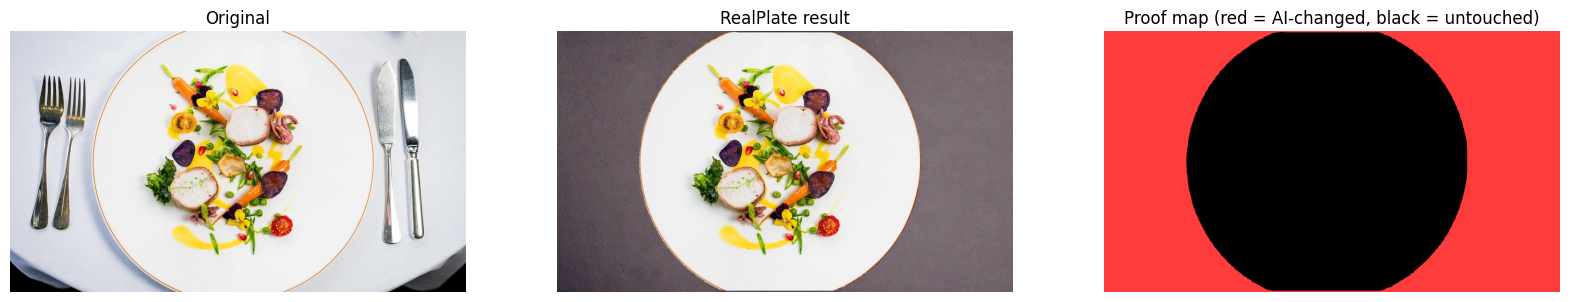

In [14]:
# 1. Composite: original pixels where the mask is white, generated pixels everywhere else
result = Image.composite(original, generated, final_mask_img)
result.save("realplate_result.png")   # PNG on purpose: JPEG compression would alter the food pixels

# 2. Verification: compare every pixel of the result against the original
orig_arr = np.array(original).astype(np.int16)
res_arr = np.array(result).astype(np.int16)
diff = np.abs(res_arr - orig_arr).sum(axis=2)        # 0 = identical pixel

inside = final_mask                                   # plate + food region
changed_inside = int((diff[inside] > 0).sum())
total_inside = int(inside.sum())
changed_outside = (diff[~inside] > 0).mean() * 100

print(f"Plate/food pixels checked:   {total_inside:,}")
print(f"Plate/food pixels changed:   {changed_inside:,}  ({changed_inside / total_inside * 100:.4f}%)")
print(f"Background pixels changed:   {changed_outside:.1f}%")
print("VERIFIED: food region is pixel-identical to the original" if changed_inside == 0
      else "WARNING: some food pixels changed")

# 3. Proof map: red = pixels the AI changed, black = untouched original pixels
proof = np.zeros((*diff.shape, 3), dtype=np.uint8)
proof[diff > 0] = [255, 60, 60]

fig, axes = plt.subplots(1, 3, figsize=(20, 5))
axes[0].imshow(original); axes[0].set_title("Original"); axes[0].axis("off")
axes[1].imshow(result); axes[1].set_title("RealPlate result"); axes[1].axis("off")
axes[2].imshow(proof); axes[2].set_title("Proof map (red = AI-changed, black = untouched)"); axes[2].axis("off")
plt.show()

Plate/food pixels changed: 0 of 566,696
VERIFIED: food untouched


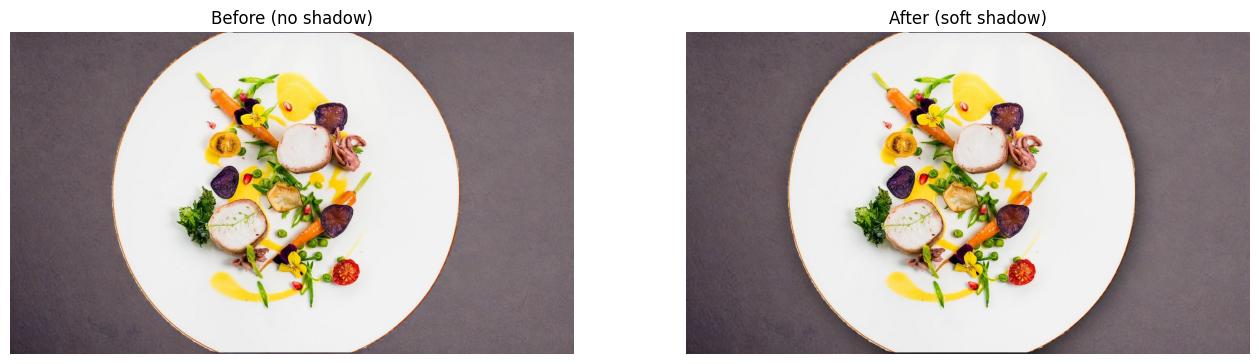

In [15]:
from PIL import ImageFilter

def add_shadow(background, mask_img, offset=(8, 14), blur=28, strength=0.55):
    """Darken the background under/around the plate. Never touches plate pixels."""
    shadow = Image.new("L", background.size, 0)
    shadow.paste(mask_img, offset)                        # shifted copy of the plate shape
    shadow = shadow.filter(ImageFilter.GaussianBlur(blur))  # soften into a shadow
    s = np.array(shadow).astype(np.float32) / 255 * strength
    bg = np.array(background).astype(np.float32) * (1 - s[..., None])
    return Image.fromarray(bg.clip(0, 255).astype(np.uint8))

def verify(original, result, mask):
    """Count how many plate/food pixels differ from the original."""
    diff = np.abs(np.array(result).astype(np.int16) - np.array(original).astype(np.int16)).sum(axis=2)
    changed = int((diff[mask] > 0).sum())
    print(f"Plate/food pixels changed: {changed:,} of {int(mask.sum()):,}")
    print("VERIFIED: food untouched" if changed == 0 else "WARNING: food pixels changed")
    return diff

shadowed_bg = add_shadow(generated, final_mask_img)
result2 = Image.composite(original, shadowed_bg, final_mask_img)
result2.save("realplate_result_shadow.png")
verify(original, result2, final_mask)

fig, axes = plt.subplots(1, 2, figsize=(16, 5))
axes[0].imshow(result); axes[0].set_title("Before (no shadow)"); axes[0].axis("off")
axes[1].imshow(result2); axes[1].set_title("After (soft shadow)"); axes[1].axis("off")
plt.show()

--- Fine dining (slate) ---


  0%|          | 0/30 [00:00<?, ?it/s]

Plate/food pixels changed: 0 of 566,696
VERIFIED: food untouched
--- Cafe brunch (marble) ---


  0%|          | 0/30 [00:00<?, ?it/s]

Plate/food pixels changed: 0 of 566,696
VERIFIED: food untouched
--- Cozy bistro (oak) ---


...

Plate/food pixels changed: 0 of 566,696
VERIFIED: food untouched
--- Clean studio (gray) ---


  0%|          | 0/30 [00:00<?, ?it/s]

Plate/food pixels changed: 0 of 566,696
VERIFIED: food untouched
--- Bar (mahogany) ---


  0%|          | 0/30 [00:00<?, ?it/s]

Plate/food pixels changed: 0 of 566,696
VERIFIED: food untouched


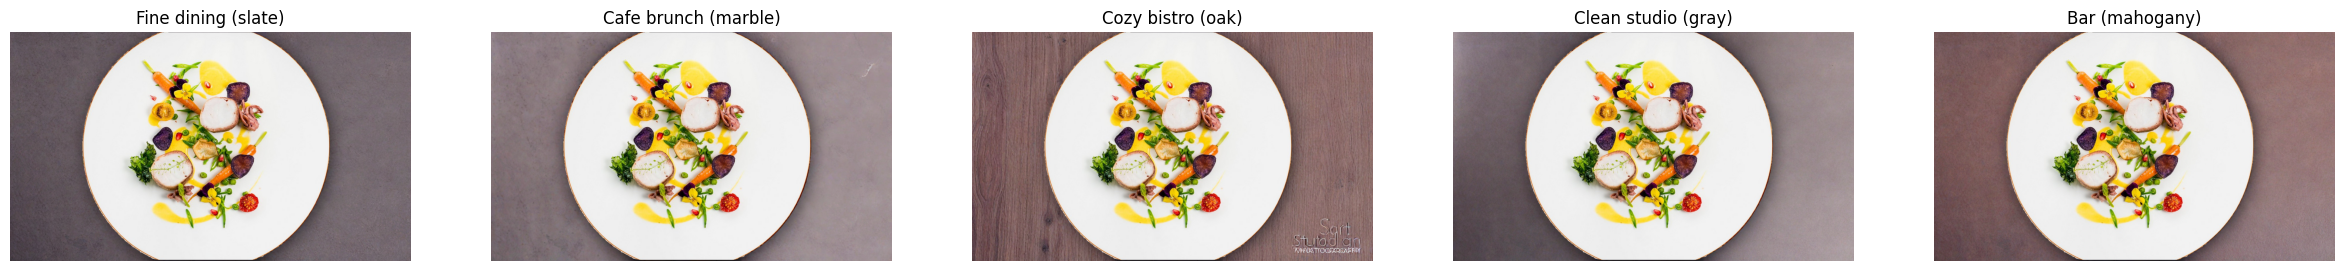

In [16]:
STYLES = {
    "Fine dining (slate)": "overhead flat lay food photography, empty dark charcoal slate tabletop with fine natural stone texture, minimClean studio (gray)udio light, fine dining, photorealistic, high detail",
    "Cafe brunch (marble)": "overhead flat lay food photography, empty polished white marble tabletop with subtle grey veining, minimalist, bright soft morning light, cafe, photorealistic, high detail",
    "Cozy bistro (oak)": "overhead flat lay food photography, empty aged dark oak wooden table with visibClean studio (gray)t, warm soft light, rusticClean studio (gray)stic, high detail",
    "Clean studio (gray)": "overhead flat lay food photography, empty brushed stainless steel tabletop, minimalist, bright crisp light, urban street food, photorealistic, high detail",
    "Bar (mahogany)": "overhead flat lay food photography, empty polished dark mahogany wood bar top with soft reflections, minimalist, moody low light, cocktail bar, photorealistic, high detail",
}
NEGATIVE = ("plate, bowl, food, fork, knife, spoon, chopsticks, cup, glass, drink, wine, herbs, garnish, "
            "napkin, props, text, watermark, hands, clutter, blurry, artifacts")

def gen_size(w, h, target=1024 * 1024):
    """Pick an SDXL size near 1 megapixel, same shape as the photo, multiples of 64."""
    scale = (target / (w * h)) ** 0.5
    return max(64, round(w * scale / 64) * 64), max(64, round(h * scale / 64) * 64)

def realplate(image, style="Fine dining (slate)", seed=42):
    image = image.convert("RGB")
    if max(image.size) > 1600:
        image.thumbnail((1600, 1600), Image.LANCZOS)

    # 1. Find the plate (Grounding DINO)
    d_in = dino_processor(images=image, text="a plate.", return_tensors="pt").to(device)
    with torch.no_grad():
        d_out = dino_model(**d_in)
        det = dino_processor.post_process_grounded_object_detection(
        d_out, input_ids=d_in.input_ids, threshold=0.3, text_threshold=0.25,
        target_sizes=[image.size[::-1]])[0]
    if len(det["boxes"]) == 0:
        raise ValueError("No plate detected. Try a photo where the plate is clearly visible.")
    box = det["boxes"][det["scores"].argmax()].tolist()

    # 2. Precise mask (SAM) + cleanup
    s_in = sam_processor(image, input_boxes=[[box]], return_tensors="pt").to(device)
    with torch.no_grad():
        s_out = sam_model(**s_in, multimask_output=False)
    raw = sam_processor.post_process_masks(
        s_out.pred_masks.cpu(), s_in["original_sizes"].cpu(), s_in["reshaped_input_sizes"].cpu())[0][0][0].numpy()
    mask = clean_mask(raw, box)
    mask_img = Image.fromarray((mask * 255).astype("uint8"))

    # 3. Generate background (SDXL inpainting on a blanked background)
    gw, gh = gen_size(*image.size)
    filled = Image.composite(image, Image.new("RGB", image.size, (110, 110, 110)), mask_img)
    bg_mask = Image.fromarray(((~mask) * 255).astype("uint8"))
    gen = pipe(
        prompt=STYLES[style], negative_prompt=NEGATIVE,
        image=filled.resize((gw, gh), Image.LANCZOS),
        mask_image=bg_mask.resize((gw, gh), Image.NEAREST),
        width=gw, height=gh, strength=1.0, guidance_scale=7.5, num_inference_steps=30,
        generator=torch.Generator(device).manual_seed(seed),
    ).images[0].resize(image.size, Image.LANCZOS)

    # 4. Shadow + paste original plate back
    result = Image.composite(image, add_shadow(gen, mask_img), mask_img)

    # 5. Verify + proof map
    diff = verify(image, result, mask)
    proof = np.zeros((*diff.shape, 3), dtype=np.uint8)
    proof[diff > 0] = [255, 60, 60]
    return result, mask_img, Image.fromarray(proof)

# Test: all 5 styles on our test image
fig, axes = plt.subplots(1, 5, figsize=(30, 5))
for ax, style in zip(axes, STYLES):
    print(f"--- {style} ---")
    out, _, _ = realplate(original, style)
    out.save(f"result_{style.split(' ')[0].lower()}.png")
    ax.imshow(out); ax.set_title(style); ax.axis("off")
plt.show()

Saving pexels-dainiktales-19834448.jpg to pexels-dainiktales-19834448 (2).jpg
Saving pexels-elizabeth-zernetska-86424040-9001223.jpg to pexels-elizabeth-zernetska-86424040-9001223.jpg

=== pexels-dainiktales-19834448 (2).jpg (4480x6720) ===


  0%|          | 0/30 [00:00<?, ?it/s]

Plate/food pixels changed: 0 of 218,270
VERIFIED: food untouched


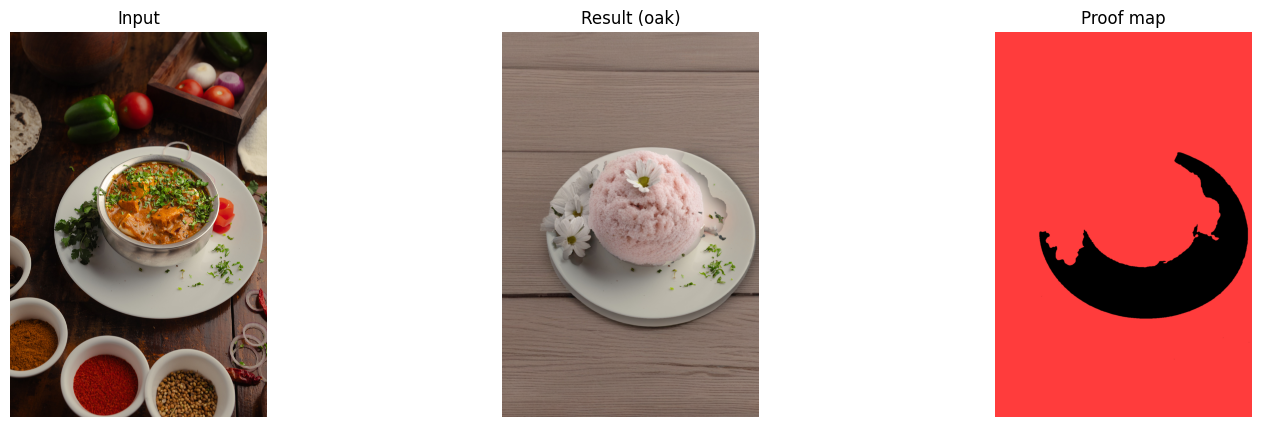


=== pexels-elizabeth-zernetska-86424040-9001223.jpg (1793x2688) ===


  0%|          | 0/30 [00:00<?, ?it/s]

Plate/food pixels changed: 0 of 388,951
VERIFIED: food untouched


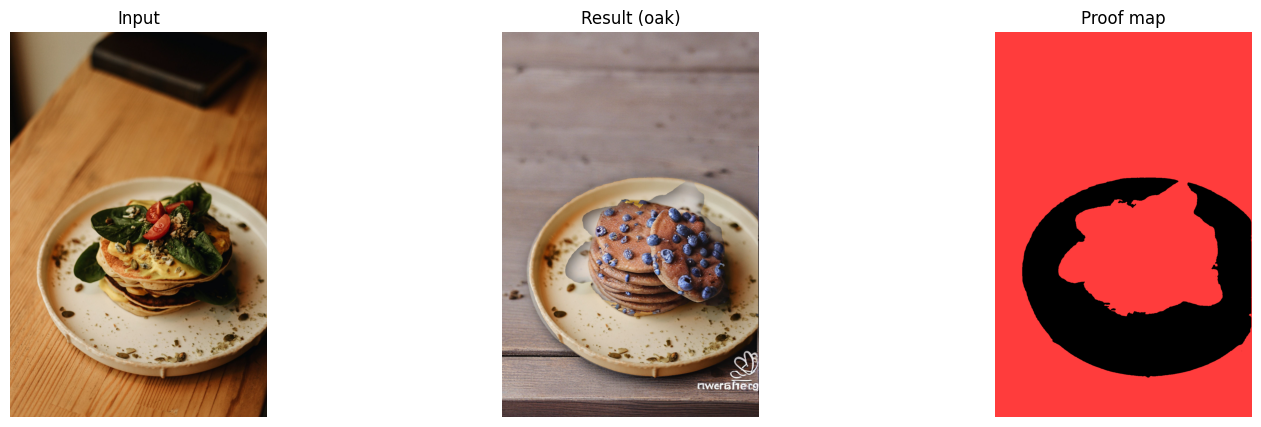

In [17]:
uploaded = files.upload()   # select BOTH photos at once (Ctrl/Cmd + click)

for name in uploaded:
    img = Image.open(name).convert("RGB")
    print(f"\n=== {name} ({img.size[0]}x{img.size[1]}) ===")
    try:
        out, mask_out, proof_out = realplate(img, "Cozy bistro (oak)")
        out.save(f"test_{name.rsplit('.', 1)[0]}.png")
        fig, axes = plt.subplots(1, 3, figsize=(18, 5))
        for ax, im, title in zip(axes, [img, out, proof_out], ["Input", "Result (oak)", "Proof map"]):
            ax.imshow(im); ax.set_title(title); ax.axis("off")
        plt.show()
    except ValueError as e:
        print("FAILED:", e)


=== original ===


/usr/local/lib/python3.13/dist-packages/transformers/models/grounding_dino/processing_grounding_dino.py:94: FutureWarning: The key `labels` is will return integer ids in `GroundingDinoProcessor.post_process_grounded_object_detection` output since v4.51.0. Use `text_labels` instead to retrieve string object names.
  warnings.warn(self.message, FutureWarning)


  kept: food (0.68)
  kept: a plate a bowl (0.47)
  kept: a bowl (0.34)
  food box score 0.68: 100% inside protected area -> OK
  SAFE TO GENERATE

=== pexels-dainiktales-19834448 (2).jpg ===
  kept: a plate (0.55)
  kept: a bowl (0.42)
  kept: food (0.35)
  food box score 0.35: 100% inside protected area -> OK
  SAFE TO GENERATE

=== pexels-elizabeth-zernetska-86424040-9001223.jpg ===
  kept: a plate a bowl (0.50)
  kept: food (0.61)
  food box score 0.61: 97% inside protected area -> OK
  SAFE TO GENERATE


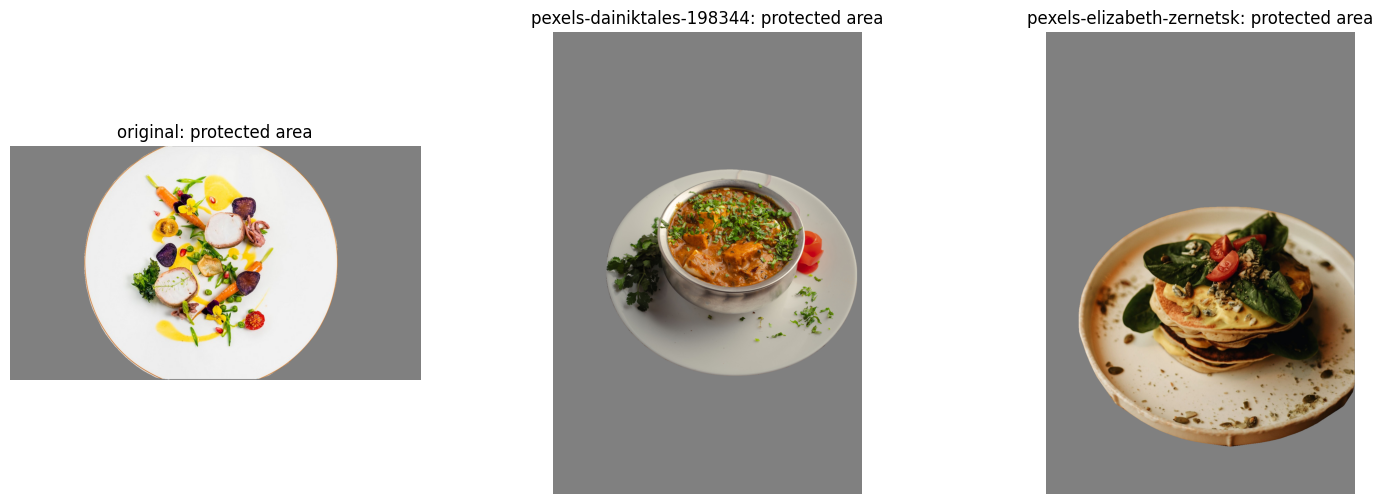

In [18]:
from scipy.spatial import ConvexHull
from PIL import ImageDraw

DISH_PROMPT = "a plate. a bowl. food."

def detect(image, prompt=DISH_PROMPT, threshold=0.3):
    d_in = dino_processor(images=image, text=prompt, return_tensors="pt").to(device)
    with torch.no_grad():
        d_out = dino_model(**d_in)
    det = dino_processor.post_process_grounded_object_detection(
        d_out, input_ids=d_in.input_ids, threshold=threshold, text_threshold=0.25,
        target_sizes=[image.size[::-1]])[0]
    labels = det.get("text_labels", det.get("labels"))
    return [(l, s.item(), b.tolist()) for l, s, b in zip(labels, det["scores"], det["boxes"])]

def box_area(b):
    return (b[2] - b[0]) * (b[3] - b[1])

def build_mask(image):
    dets = detect(image)
    if not dets:
        raise ValueError("No dish detected. Try a clearer photo of the plate.")

    # The dish = the biggest plate/bowl detection
    vessels = [d for d in dets if "plate" in d[0] or "bowl" in d[0]]
    main = max(vessels or dets, key=lambda d: box_area(d[2]))
    mx0, my0, mx1, my1 = main[2]

    # Keep every detection whose centre sits inside the dish (ignores side bowls, props, etc.)
    keep = [d for d in dets
            if mx0 <= (d[2][0] + d[2][2]) / 2 <= mx1 and my0 <= (d[2][1] + d[2][3]) / 2 <= my1]

    # SAM on all kept boxes at once, then merge
    s_in = sam_processor(image, input_boxes=[[d[2] for d in keep]], return_tensors="pt").to(device)
    with torch.no_grad():
        s_out = sam_model(**s_in, multimask_output=False)
    masks = sam_processor.post_process_masks(
        s_out.pred_masks.cpu(), s_in["original_sizes"].cpu(), s_in["reshaped_input_sizes"].cpu())[0]
    union = masks[:, 0].any(dim=0).numpy()

    # Convex hull: closes gaps where food overhangs the rim
    ys, xs = np.nonzero(union)
    pts = np.column_stack([xs, ys])
    hull = ConvexHull(pts)
    hull_img = Image.new("L", image.size, 0)
    ImageDraw.Draw(hull_img).polygon([tuple(map(int, p)) for p in pts[hull.vertices]], fill=255)
    return np.array(hull_img) > 0, keep

def food_coverage_check(mask, keep):
    """Every detected food box must be mostly inside the protected region."""
    ok = True
    for label, score, b in keep:
        if "food" not in label:
            continue
        x0, y0, x1, y1 = [int(round(v)) for v in b]
        cov = mask[y0:y1, x0:x1].mean() * 100
        flag = "OK" if cov >= 85 else "NOT PROTECTED"
        ok &= cov >= 85
        print(f"  food box score {score:.2f}: {cov:.0f}% inside protected area -> {flag}")
    print("  SAFE TO GENERATE" if ok else "  UNSAFE: food may be repainted, do not generate")
    return ok

# Test masks on all 3 photos
test_images = {"original": original}
test_images.update({name: Image.open(name).convert("RGB") for name in uploaded})

fig, axes = plt.subplots(1, len(test_images), figsize=(6 * len(test_images), 6))
for ax, (name, img) in zip(axes, test_images.items()):
    if max(img.size) > 1600:
        img.thumbnail((1600, 1600), Image.LANCZOS)
    print(f"\n=== {name} ===")
    m, keep = build_mask(img)
    for label, score, b in keep:
        print(f"  kept: {label} ({score:.2f})")
    food_coverage_check(m, keep)
    preview = Image.composite(img, Image.new("RGB", img.size, (128, 128, 128)), Image.fromarray((m * 255).astype("uint8")))
    ax.imshow(preview); ax.set_title(f"{name[:25]}: protected area"); ax.axis("off")
plt.show()


=== pexels-dainiktales-19834448 (2).jpg ===
  food box score 0.35: 100% inside protected area -> OK
  SAFE TO GENERATE


  0%|          | 0/30 [00:00<?, ?it/s]

Plate/food pixels changed: 0 of 488,395
VERIFIED: food untouched


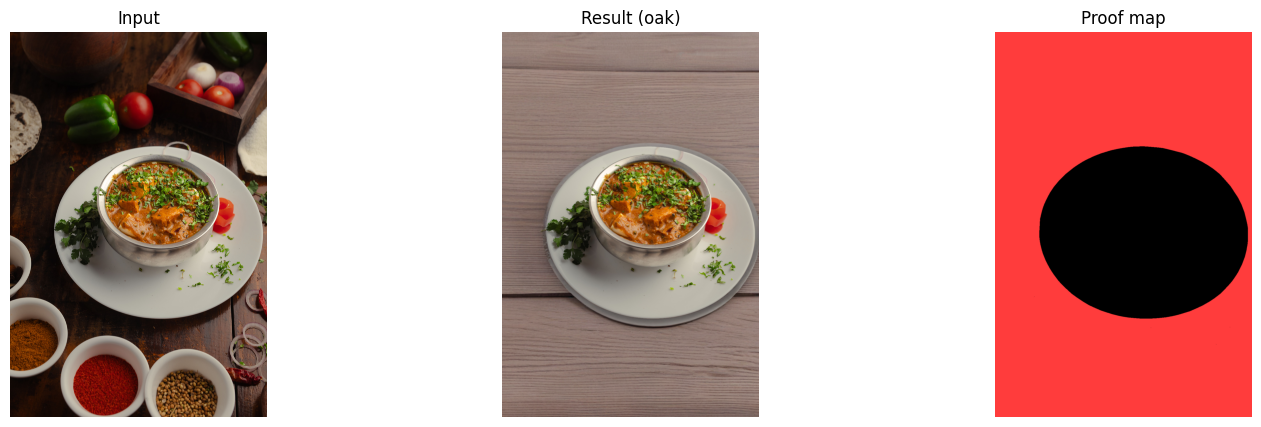


=== pexels-elizabeth-zernetska-86424040-9001223.jpg ===
  food box score 0.61: 97% inside protected area -> OK
  SAFE TO GENERATE


  0%|          | 0/30 [00:00<?, ?it/s]

Plate/food pixels changed: 0 of 650,162
VERIFIED: food untouched


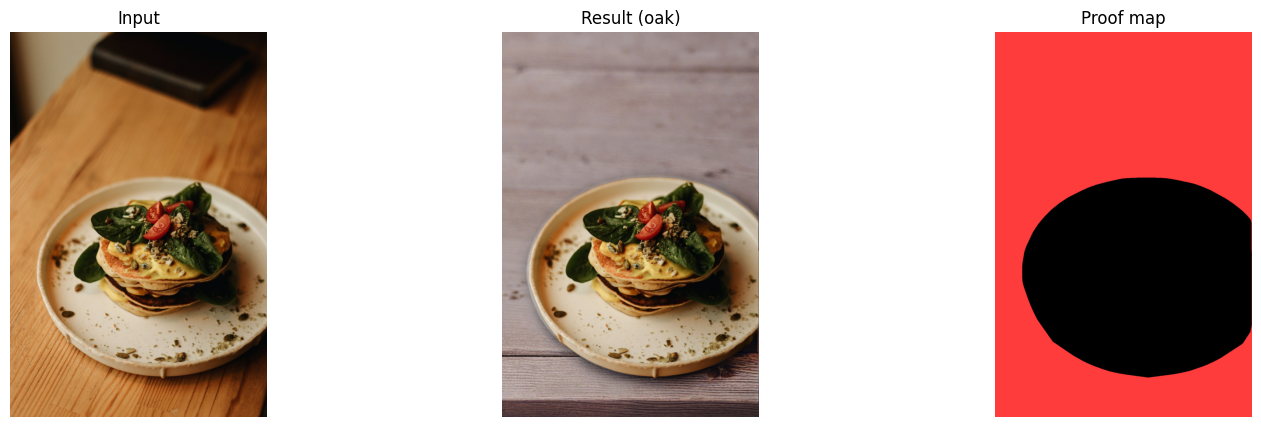

In [19]:
def realplate(image, style="Fine dining (slate)", seed=42):
    image = image.convert("RGB")
    if max(image.size) > 1600:
        image.thumbnail((1600, 1600), Image.LANCZOS)

    # 1+2. Detect plate/bowl/food, SAM each, merge with convex hull
    mask, keep = build_mask(image)
    if not food_coverage_check(mask, keep):
        raise ValueError("Food is not fully inside the protected area. Refusing to generate.")
    mask_img = Image.fromarray((mask * 255).astype("uint8"))

    # 3. Generate background (SDXL inpainting on a blanked background)
    gw, gh = gen_size(*image.size)
    filled = Image.composite(image, Image.new("RGB", image.size, (110, 110, 110)), mask_img)
    bg_mask = Image.fromarray(((~mask) * 255).astype("uint8"))
    gen = pipe(
        prompt=STYLES[style], negative_prompt=NEGATIVE,
        image=filled.resize((gw, gh), Image.LANCZOS),
        mask_image=bg_mask.resize((gw, gh), Image.NEAREST),
        width=gw, height=gh, strength=1.0, guidance_scale=7.5, num_inference_steps=30,
        generator=torch.Generator(device).manual_seed(seed),
    ).images[0].resize(image.size, Image.LANCZOS)

    # 4. Shadow + paste original dish back
    result = Image.composite(image, add_shadow(gen, mask_img), mask_img)

    # 5. Verify + proof map
    diff = verify(image, result, mask)
    proof = np.zeros((*diff.shape, 3), dtype=np.uint8)
    proof[diff > 0] = [255, 60, 60]
    return result, mask_img, Image.fromarray(proof)

# Rerun the two photos that failed before
titles = ["Input", "Result (oak)", "Proof map"]

for name in uploaded:
    img = Image.open(name).convert("RGB")
    print(f"\n=== {name} ===")
    try:
        out, _, proof_out = realplate(img, "Cozy bistro (oak)")
        out.save(f"test_{name.rsplit('.', 1)[0]}_v2.png")
        fig, axes = plt.subplots(1, 3, figsize=(18, 5))
        panels = [img, out, proof_out]
        for ax, im, title in zip(axes, panels, titles):
            ax.imshow(im)
            ax.set_title(title)
            ax.axis("off")
        plt.show()
    except ValueError as e:
        print("REFUSED:", e)

In [20]:
from importlib.metadata import version, PackageNotFoundError

def v(pkg):
    try:
        return version(pkg)
    except PackageNotFoundError:
        return "not installed"

watch = ["gradio", "numpy", "pillow", "torch", "transformers", "diffusers", "huggingface-hub"]
before = {p: v(p) for p in watch}

%pip install -q gradio

after = {p: v(p) for p in watch}
for p in watch:
    mark = "" if before[p] == after[p] else "   <-- CHANGED"
    print(f"{p:16} {before[p]:>14} -> {after[p]}{mark}")

gradio                   6.29.0 -> 6.29.0
numpy                     2.1.3 -> 2.1.3
pillow                   11.3.0 -> 11.3.0
torch              2.11.0+cu130 -> 2.11.0+cu130
transformers             5.18.0 -> 5.18.0
diffusers                0.40.0 -> 0.40.0
huggingface-hub          1.33.0 -> 1.33.0


In [21]:
import gradio as gr

def run_realplate(image, style, seed):
    if image is None:
        raise gr.Error("Upload a food photo first.")
    try:
        result, mask_img, proof = realplate(image, style, int(seed))
    except ValueError as e:
        raise gr.Error(str(e))

    mask_arr = np.array(mask_img) > 0
    changed = np.array(proof)[..., 0] > 0
    dish_px = int(mask_arr.sum())
    changed_dish = int((changed & mask_arr).sum())
    bg_pct = changed[~mask_arr].mean() * 100

    if changed_dish == 0:
        status = (f"### ✅ Verified authentic\n"
                  f"**0 of {dish_px:,}** dish pixels changed. "
                  f"The AI generated {bg_pct:.0f}% of the background and never touched the food.")
    else:
        status = f"### ⚠️ {changed_dish:,} dish pixels changed. Do not use this image."

    before = image.convert("RGB").resize(result.size)
    return (before, result), proof, status

print("run_realplate ready")

run_realplate ready


In [22]:
with gr.Blocks(title="RealPlate") as demo:
    gr.Markdown("# 🍽️ RealPlate\nAI restyles the table. Your food stays real, verified pixel by pixel.")
    with gr.Row():
        with gr.Column():
            inp = gr.Image(type="pil", label="Your food photo")
            style = gr.Dropdown(list(STYLES), value="Cozy bistro (oak)", label="Restaurant style")
            seed = gr.Number(value=42, precision=0, label="Variation")
            btn = gr.Button("Generate", variant="primary")
        with gr.Column():
            slider = gr.ImageSlider(label="Before / After", type="pil")
            status = gr.Markdown()
            proof = gr.Image(label="Proof map: red = AI, black = original", type="pil")
    btn.click(run_realplate, inputs=[inp, style, seed], outputs=[slider, proof, status])

print("Launching...")
demo.launch(share=True, prevent_thread_lock=True)
print("Public URL:", demo.share_url)

Launching...
Colab notebook detected. To show errors in colab notebook, set debug=True in launch()
* Running on public URL: https://77833392d01ba7e325.gradio.live

This share link is temporary and will last for up to 1 week (best effort). For free permanent hosting and GPU upgrades, run `gradio deploy` from the terminal in the working directory to deploy to Hugging Face Spaces (https://huggingface.co/spaces)


Public URL: https://77833392d01ba7e325.gradio.live


In [28]:
def run_realplate(image, style, seed, custom_prompt=""):
    if image is None:
        raise gr.Error("Upload a food photo first.")
    chosen = style
    if custom_prompt and custom_prompt.strip():
        STYLES["Custom"] = custom_prompt.strip()
        chosen = "Custom"
    try:
        result, mask_img, proof = realplate(image, chosen, int(seed))
    except ValueError as e:
        raise gr.Error(str(e))

    mask_arr = np.array(mask_img) > 0
    changed = np.array(proof)[..., 0] > 0
    dish_px = int(mask_arr.sum())
    changed_dish = int((changed & mask_arr).sum())
    bg_pct = changed[~mask_arr].mean() * 100

    if changed_dish == 0:
        status = (f"### ✅ Verified authentic\n"
                  f"**0 of {dish_px:,}** dish pixels changed. "
                  f"The AI generated {bg_pct:.0f}% of the background and never touched the food.")
    else:
        status = f"### ⚠️ {changed_dish:,} dish pixels changed. Do not use this image."

    before = image.convert("RGB").resize(result.size)
    return (before, result), proof, status

print("run_realplate v2 ready")

run_realplate v2 ready


In [24]:
demo.close()   # shut down the old app first

with gr.Blocks(title="RealPlate") as demo:
    gr.Markdown("# 🍽️ RealPlate\nAI restyles the table. Your food stays real, verified pixel by pixel.")
    with gr.Row():
        with gr.Column():
            inp = gr.Image(type="pil", label="Your food photo", height=360)
            style = gr.Dropdown([s for s in STYLES if s != "Custom"], value="Cozy bistro (oak)", label="Restaurant style")
            custom = gr.Textbox(label="Custom background prompt (optional, overrides the style)", lines=2,
                                placeholder="overhead flat lay food photography, ...")
            seed = gr.Number(value=42, precision=0, label="Variation")
            btn = gr.Button("Generate", variant="primary")
        with gr.Column():
            slider = gr.ImageSlider(label="Before / After", type="pil", height=360)
            status = gr.Markdown()
            proof = gr.Image(label="Proof map: red = AI, black = original", type="pil", height=240)
    btn.click(run_realplate, inputs=[inp, style, seed, custom], outputs=[slider, proof, status])

print("Launching...")
demo.launch(share=True, prevent_thread_lock=True)
print("Public URL:", demo.share_url)

Closing server running on port: 7860
Launching...
Colab notebook detected. To show errors in colab notebook, set debug=True in launch()
* Running on public URL: https://650c5987857e9c8c6f.gradio.live

This share link is temporary and will last for up to 1 week (best effort). For free permanent hosting and GPU upgrades, run `gradio deploy` from the terminal in the working directory to deploy to Hugging Face Spaces (https://huggingface.co/spaces)


Public URL: https://650c5987857e9c8c6f.gradio.live


/usr/local/lib/python3.13/dist-packages/transformers/models/grounding_dino/processing_grounding_dino.py:94: FutureWarning: The key `labels` is will return integer ids in `GroundingDinoProcessor.post_process_grounded_object_detection` output since v4.51.0. Use `text_labels` instead to retrieve string object names.
  warnings.warn(self.message, FutureWarning)


  0%|          | 0/30 [00:00<?, ?it/s]

  0%|          | 0/30 [00:00<?, ?it/s]

  0%|          | 0/27 [00:00<?, ?it/s]

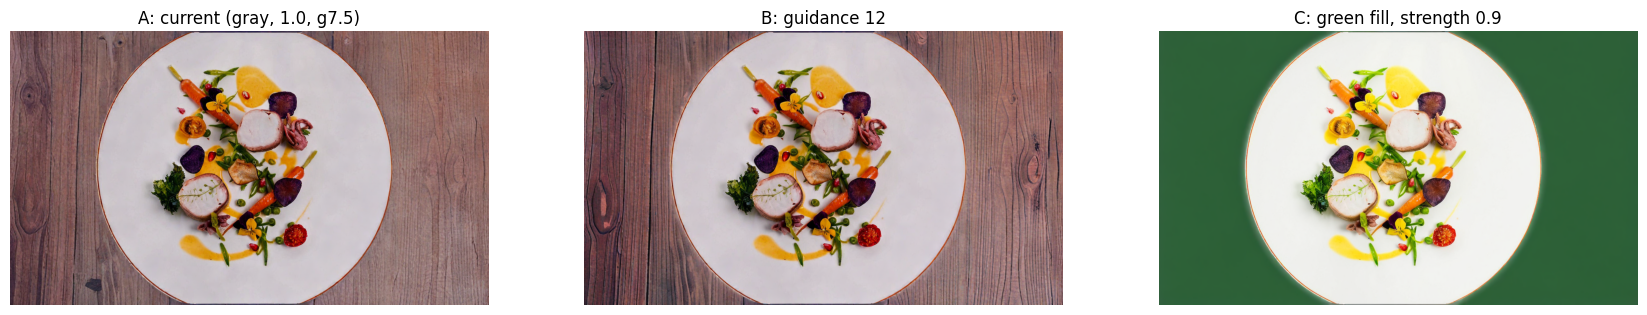

In [25]:
m, keep = build_mask(original)
m_img = Image.fromarray((m * 255).astype("uint8"))
gw, gh = gen_size(*original.size)
bgm = Image.fromarray(((~m) * 255).astype("uint8")).resize((gw, gh), Image.NEAREST)

green_prompt = ("overhead flat lay food photography, rustic dark green painted wooden table "
                "with chipped paint, warm soft light, photorealistic, high detail")

def try_bg(fill_rgb, strength, guidance):
    blank = Image.new("RGB", original.size, fill_rgb)
    filled = Image.composite(original, blank, m_img).resize((gw, gh), Image.LANCZOS)
    return pipe(prompt=green_prompt, negative_prompt=NEGATIVE, image=filled, mask_image=bgm,
                width=gw, height=gh, strength=strength, guidance_scale=guidance,
                num_inference_steps=30, generator=torch.Generator(device).manual_seed(42)).images[0]

tests = [
    ("A: current (gray, 1.0, g7.5)", (110, 110, 110), 1.0, 7.5),
    ("B: guidance 12", (110, 110, 110), 1.0, 12),
    ("C: green fill, strength 0.9", (40, 90, 50), 0.9, 7.5),
]

fig, axes = plt.subplots(1, 3, figsize=(21, 5))
for ax, (title, fill, s, g) in zip(axes, tests):
    ax.imshow(try_bg(fill, s, g))
    ax.set_title(title)
    ax.axis("off")
plt.show()

  food box score 0.68: 100% inside protected area -> OK
  SAFE TO GENERATE


  0%|          | 0/27 [00:00<?, ?it/s]

Plate/food pixels changed: 0 of 568,381
VERIFIED: food untouched


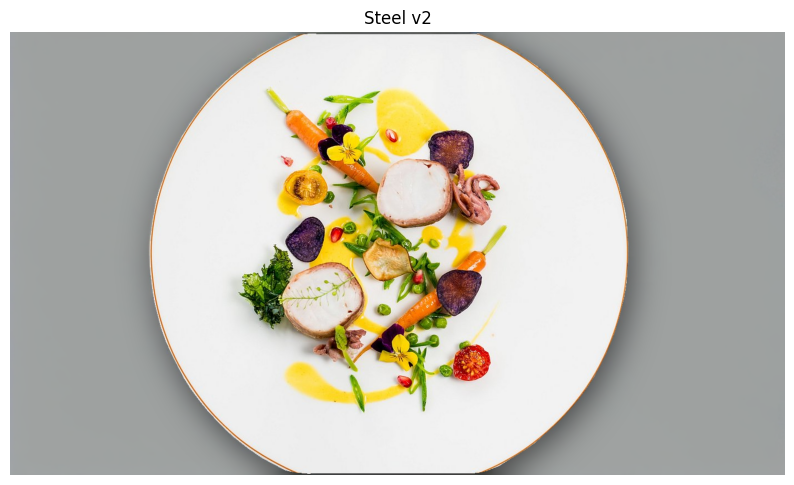

In [26]:
STYLE_COLORS = {
    "Fine dining (slate)": (55, 58, 62),
    "Cafe brunch (marble)": (225, 225, 222),
    "Cozy bistro (oak)": (110, 75, 45),
    "Clean studio (gray)": (150, 155, 160),
    "Bar (mahogany)": (75, 35, 25),
}

def realplate(image, style="Fine dining (slate)", seed=42, fill_rgb=None):
    image = image.convert("RGB")
    if max(image.size) > 1600:
        image.thumbnail((1600, 1600), Image.LANCZOS)

    # 1+2. Detect plate/bowl/food, SAM each, merge with convex hull
    mask, keep = build_mask(image)
    if not food_coverage_check(mask, keep):
        raise ValueError("Food is not fully inside the protected area. Refusing to generate.")
    mask_img = Image.fromarray((mask * 255).astype("uint8"))

    # 3. Generate background, starting from the style's base color
    if fill_rgb is None:
        fill_rgb = STYLE_COLORS.get(style, (110, 110, 110))
    gw, gh = gen_size(*image.size)
    filled = Image.composite(image, Image.new("RGB", image.size, fill_rgb), mask_img)
    bg_mask = Image.fromarray(((~mask) * 255).astype("uint8"))
    gen = pipe(
        prompt=STYLES[style], negative_prompt=NEGATIVE,
        image=filled.resize((gw, gh), Image.LANCZOS),
        mask_image=bg_mask.resize((gw, gh), Image.NEAREST),
        width=gw, height=gh, strength=0.9, guidance_scale=7.5, num_inference_steps=30,
        generator=torch.Generator(device).manual_seed(seed),
    ).images[0].resize(image.size, Image.LANCZOS)

    # 4. Shadow + paste original dish back
    result = Image.composite(image, add_shadow(gen, mask_img), mask_img)

    # 5. Verify + proof map
    diff = verify(image, result, mask)
    proof = np.zeros((*diff.shape, 3), dtype=np.uint8)
    proof[diff > 0] = [255, 60, 60]
    return result, mask_img, Image.fromarray(proof)

# Quick test: steel
out, _, _ = realplate(original, "Clean studio (gray)")
plt.figure(figsize=(10, 6)); plt.imshow(out); plt.axis("off"); plt.title("Steel v2"); plt.show()

/tmp/ipykernel_9377/1422118358.py:6: DeprecationWarning: 'mode' parameter is deprecated and will be removed in Pillow 13 (2026-10-15)
  noise = np.array(Image.fromarray(noise, mode="F").resize((w, h), Image.BICUBIC))


  0%|          | 0/27 [00:00<?, ?it/s]

  0%|          | 0/28 [00:00<?, ?it/s]

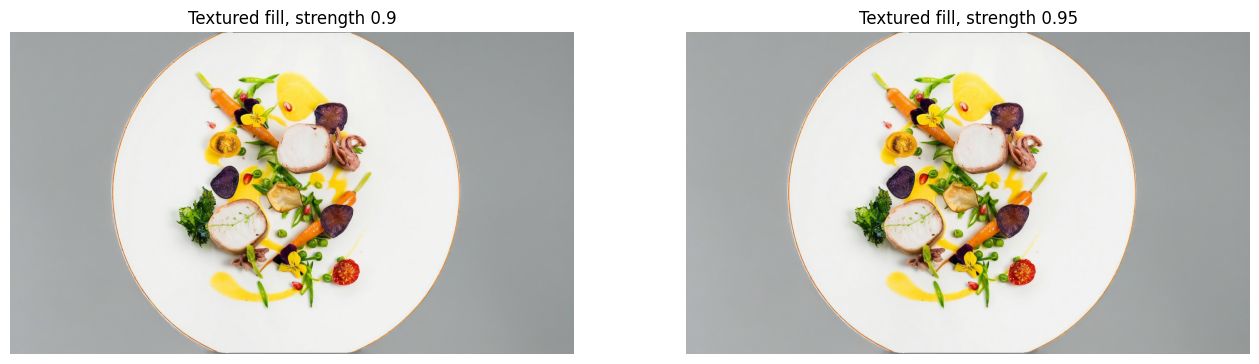

In [27]:
def textured_fill(size, rgb, amount=30, seed=0):
    """Base color + soft blotchy noise, same across R/G/B so the color doesn't shift."""
    w, h = size
    rng = np.random.default_rng(seed)
    noise = rng.normal(0, amount, (max(1, h // 16), max(1, w // 16))).astype(np.float32)
    noise = np.array(Image.fromarray(noise, mode="F").resize((w, h), Image.BICUBIC))
    arr = np.array(rgb, dtype=np.float32)[None, None, :] + noise[..., None]
    return Image.fromarray(arr.clip(0, 255).astype("uint8"))

steel_rgb = STYLE_COLORS["Clean studio (gray)"]
steel_prompt = STYLES["Clean studio (gray)"]

def try_steel(strength):
    fill = textured_fill(original.size, steel_rgb)
    filled = Image.composite(original, fill, m_img).resize((gw, gh), Image.LANCZOS)
    return pipe(prompt=steel_prompt, negative_prompt=NEGATIVE, image=filled, mask_image=bgm,
                width=gw, height=gh, strength=strength, guidance_scale=7.5,
                num_inference_steps=30, generator=torch.Generator(device).manual_seed(42)).images[0]

fig, axes = plt.subplots(1, 2, figsize=(16, 5))
for ax, s in zip(axes, [0.9, 0.95]):
    ax.imshow(try_steel(s))
    ax.set_title(f"Textured fill, strength {s}")
    ax.axis("off")
plt.show()